# Step 1 : Introduction to CNNs


Convolutional Neural Network, neural network designed for analyzing visual data. This model learn to 'see' the world by identifying patterns.
It recognize patterns with a grid-like structure.

The model process images by passing them through multiple layers, each of them identifying a feature (edges, lines, ...). The deeper layers recognize more complex patterns (shapes, whole objects, ...).

The layers :
- Convolutional layer : identifying simple feature (straight edge, curve, color, ...)
- Activation layer : reviewing of the map created by the cconvolutional layer, it keeps the strong signals and get rid of the weak ones. It ensures that only the important features are kept, preventing noise from cluttering the process
- Pooling layer : summarize the findings from small patches of the feature map, reducing the size of the data
- Fully connected layer : looks at the high-level combination features (whiskers, ...), draws a conclusion (cat or dog)

# Step 2: Dataset Exploration

In [2]:
# imports
import os
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

base_dir = "cats_and_dogs_filtered"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")

### How many cat and dog images are there in the training and validation directories?

In [3]:
# Image count
def count_images(directory):
    counts = {}
    for cls in sorted(os.listdir(directory)):
        cls_path = os.path.join(directory, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts

train_counts = count_images(train_dir)
val_counts = count_images(val_dir)

print("Train : ", train_counts)
print("Validation : ", val_counts)

Train :  {'cats': 1000, 'dogs': 1000}
Validation :  {'cats': 500, 'dogs': 500}


##### There are :

|      | training set | validation set |
|------|--------------|----------------|
| cats | 1000 cats    | 500 cats       |
| dogs | 1000 dogs    | 500 dogs       |


##### This means a class distribution of 50% each.

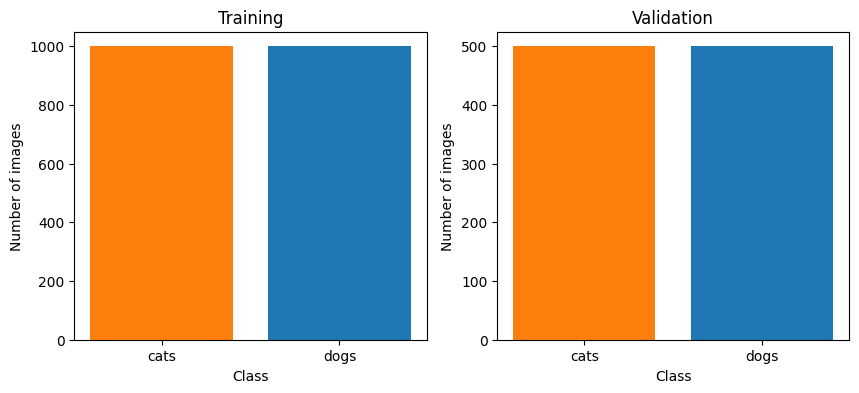

In [4]:
#Vizualization :
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, counts, title in zip(
    axes,
    [train_counts, val_counts],
    ["Training", "Validation"]
):
    ax.bar(
        counts.keys(),
        counts.values(),
        color=["tab:orange", "tab:blue"]
    )

    ax.set_title(title)
    ax.set_ylabel("Number of images")
    ax.set_xlabel("Class")

plt.show()

## Create the dataset :

In [ ]:
# Image parameters
IMG_SIZE = (150, 150)
BATCH_SIZE = 100
SEED = 42


In [7]:
def create_datasets(IMG_SIZE : tuple[int,int], BATCH_SIZE=100 , SEED=10 , validationsplit=0.2) -> tuple[tf.data.Dataset]:
    train_dataset = tf.keras.utils.image_dataset_from_directory(
        train_dir,
        validation_split=validationsplit,
        subset="training", 
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    test_dataset = tf.keras.utils.image_dataset_from_directory(
        train_dir,
        validation_split=validationsplit,
        subset="validation", 
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    val_dataset = tf.keras.utils.image_dataset_from_directory(
        val_dir,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    return train_dataset, test_dataset, val_dataset

In [17]:
train_dataset, test_dataset, validation_dataset = create_datasets(IMG_SIZE, BATCH_SIZE, SEED)

Found 2000 files belonging to 2 classes.
Using 1600 files for training.
Found 2000 files belonging to 2 classes.
Using 400 files for validation.
Found 1000 files belonging to 2 classes.


In [18]:
print(f"There are : {len(train_dataset)*BATCH_SIZE} images inside the train_dataset")
print(f"There are : {len(test_dataset)*BATCH_SIZE} images inside the test_dataset")
print(f"There are : {len(validation_dataset)*BATCH_SIZE} images inside the validation_dataset")

There are : 1600 images inside the train_dataset
There are : 400 images inside the test_dataset
There are : 1000 images inside the validation_dataset


### Vizualize images from the dataset :

In [14]:
def display_image(dataset, classes):
    plt.figure(figsize=(10, 10))
    i=0
    for images, labels in dataset.take(2):
        ax = plt.subplot(1, 2, i + 1)
        plt.imshow(images[0].numpy().astype("uint8"))
        plt.title(classes[labels[0]])
        plt.axis("off")
        i+=1

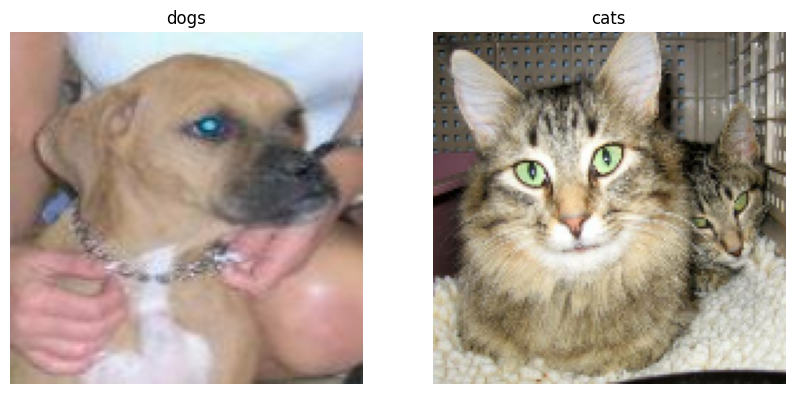

In [15]:
display_image(train_dataset,train_dataset.class_names)

# Step 3: Build Your CNN Model

In [ ]:
# Model parameters :

In [ ]:

def create_model(IMG_SIZE : tuple[int,int], padding = None, Conv2D_start_filters=32, Conv2D_kernel_size=(3,3), 
                 Conv2D_strides=(1,1),Conv2D_dilation_rate = (1,1), Conv_padding = "same",  
                 Pooling_Pool_size=(2,2), Pooling_strides=None, Pool_padding= "valid",
                 Dense_units=128, 
                 Dropout_rate=0, Dropout_Seed=24,
                 Data_augmentation=False,
                 Print=True) -> tf.keras.Sequential :
    """
    - Padding : Value is "same" or "valid" represents if we use pixels outside the image (set to 0)
    There are two specific values for the Convolution and the pooling which can be set separately.
    But if this global value is set it will overwrite that choice.

    - Conv2D_Start filter is the number of filter for the first layer of Convolution.
    It will then double at each layer.
    - Conv2D_kernel_size represents the size of pixel taken each time the convolution is calculated.
    - Conv2D_strides represents the number of skipped pixel each time the convolution moves.
    - Conv2D_dilation_rate represents the number of pixels in between two kernel pixels.

    - Pooling_Pool_size represents by how much we reduce the IMG size 
    - Pooling_Strides represents the number of skipped pixel each time the pooling moves.
    Can be left 'None' and will be calculated from the pool_size.

    - Dense_units represents the number of units we use in the Dense layer.

    - Dropout_rate is a percentage, it represents the number of forgotten images each time.
    - Dropout_Seed represents a seed to always forget the same images.

    - Data_augmentation is a boolean value to set to True if you want to use data_augmentation.

    - Print, Do we print the summary or not?
    """
    IMG_size_with_pixel_colors = (IMG_SIZE[0], IMG_SIZE[1], 3)

    #If a global value for padding is given use it for both types.
    if (padding != None):
        Conv_padding = padding
        Pool_padding = padding

    model = tf.keras.Sequential([

        # Normalize pixel values to [0, 1] range
        tf.keras.layers.Rescaling(1./255, input_shape=(IMG_size_with_pixel_colors), name="Pixel value Rescaling"), 

        # Data augmentation
        tf.keras.layers.RandomFlip("horizontal",name="Data Augmentation, horizontal flip") if Data_augmentation else tf.keras.layers.Identity(name="Data augmentation is set to False_1"),
        tf.keras.layers.RandomFlip("vertical",name="Data Augmentation, vertical flip") if Data_augmentation else tf.keras.layers.Identity(name="Data augmentation is set to False_2"),
        tf.keras.layers.RandomZoom(0.2, name="Data Augmentation, Random Zoom") if Data_augmentation else tf.keras.layers.Identity(name="Data augmentation is set to False_3"),

        tf.keras.layers.Conv2D(Conv2D_start_filters, Conv2D_kernel_size , Conv2D_strides , Conv_padding , dilation_rate=Conv2D_dilation_rate , activation="relu", name="Layer1 Convolution"),
        tf.keras.layers.MaxPool2D(Pooling_Pool_size, Pooling_strides , Pool_padding, name="Layer1 MaxPooling"),

        tf.keras.layers.Conv2D(2*Conv2D_start_filters, Conv2D_kernel_size , Conv2D_strides , Conv_padding , dilation_rate=Conv2D_dilation_rate , activation="relu", name="Layer2 Convolution"),
        tf.keras.layers.MaxPool2D(Pooling_Pool_size, Pooling_strides , Pool_padding, name="Layer2 MaxPooling"),

        tf.keras.layers.Conv2D(4*Conv2D_start_filters, Conv2D_kernel_size , Conv2D_strides , Conv_padding , dilation_rate=Conv2D_dilation_rate , activation="relu", name="Layer3 Convolution"),
        tf.keras.layers.MaxPool2D(Pooling_Pool_size, Pooling_strides , Pool_padding, name="Layer3 MaxPooling"),

        tf.keras.layers.Conv2D(8*Conv2D_start_filters, Conv2D_kernel_size , Conv2D_strides , Conv_padding , dilation_rate=Conv2D_dilation_rate , activation="relu", name="Layer4 Convolution"),
        tf.keras.layers.MaxPool2D(Pooling_Pool_size, Pooling_strides , Pool_padding, name="Layer4 MaxPooling"),

        tf.keras.layers.Flatten(name="Flatten images to use the Dense layer"),

        tf.keras.layers.Dense(Dense_units, activation="relu", name="Dense layer"),

        # Désactive Dropout_rate% des neurones aléatoirement
        tf.keras.layers.Dropout(Dropout_rate, seed=Dropout_Seed, name=f"{"Unused" if Dropout_rate==0 else ""} Dropout layer"),  

        tf.keras.layers.Dense(1, activation="sigmoid", name="Last deliberation layer.")
    ])

    if (Print) :
        model.summary()

    return model

In [30]:
model = create_model(IMG_SIZE)

c:\Users\alexi\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\preprocessing\tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


ValueError: All layers added to a Sequential model should have unique names. Name 'Data augmentation is set to False' is already the name of a layer in this model. Update the `name` argument to pass a unique name.

# Step 4: Train the Model

# Step 5: Evaluate the Model on the test set

# Step 6: Try to Improve the Model

# Bonus Challenge: Transfer Learning